# NB04 — Stage 2 Part 1: 5-Fold CV + Negative-Result Metrics

**Part 1 (detection only):** Oral Stage 1 → Tufts gaze fine-tune with **5-fold CV** on **900** images (former train 800 + val 100 merged); held-out **100 test** never used for model selection.

| Setting | Value |
|---|---|
| CV | `num_folds: 5` stratified on `train_split.csv` fold column |
| Train / CV-val | ~720 / ~180 per fold (**900** pool) |
| Held-out test | `test_split.csv` (100) — reported with bootstrap CI |
| Baselines | Stage 1 transfer vs Stage 2 gaze vs optional λ=0 ablation |
| Stats output | `results/stage2_part1_negative_report.json` |

**Resume:** per-fold checkpoints `stage2_gaze_fold{k}_last.pth`.


In [2]:
import sys, os
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    pass

Mounted at /content/drive


In [3]:
# === Colab setup (plan §1.2) ===
try:
    from google.colab import drive
except ImportError:
    pass
import os, sys, json, shutil, glob, zipfile, inspect, math, statistics
import torch
import numpy as np
import pandas as pd
CODE_DIR = '/content/dental_code'
LOCAL_DATA = '/content/dental_data'
LOCAL_ZIP_CACHE = '/content/dental_zip_cache'
os.makedirs(CODE_DIR, exist_ok=True)
def find_project_root():
    candidates = []
    shortcut_base = '/content/drive/.shortcut-targets-by-id'
    if os.path.isdir(shortcut_base):
        for entry in os.listdir(shortcut_base):
            candidates.append(os.path.join(shortcut_base, entry, 'DENTAL'))
    candidates += [
        '/content/drive/MyDrive/DENTAL',
        os.path.abspath('..') if os.path.basename(os.getcwd()) == 'Notebooks' else None,
        os.getcwd(),
    ]
    for p in candidates:
        if p and os.path.isfile(os.path.join(p, 'config.json')):
            return os.path.abspath(p)
    raise FileNotFoundError(
        'Cannot locate DENTAL project (config.json). Mount Drive and open from Notebooks/.'
    )
def upgrade_dental_dataset_hybrid(code_dir, project_root):
    """Patch stale Drive copy so DentalDataset accepts image_root."""
    path = os.path.join(code_dir, 'dental_dataset.py')
    with open(path, 'r', encoding='utf-8') as f:
        text = f.read()
    if 'image_root' in text:
        return False
    text = text.replace(
        'def __init__(self, csv_path, project_root, augment=False):',
        'def __init__(self, csv_path, project_root, augment=False, image_root=None):',
    )
    text = text.replace(
        '        self.root         = project_root\n        self.augment      = augment',
        '        self.root         = project_root\n        self.image_root   = image_root or project_root\n        self.augment      = augment',
    )
    text = text.replace(
        '        full = path if os.path.isabs(path) else os.path.join(self.root, path)\n        img = Image.open(full).convert',
        '        full = path if os.path.isabs(path) else os.path.join(self.image_root, path)\n        img = Image.open(full).convert',
        1,
    )
    text = text.replace(
        'def build_dataloaders(CONFIG, project_root, batch_size=None, fold=None, smoke_test=False):',
        'def build_dataloaders(CONFIG, project_root, batch_size=None, fold=None, smoke_test=False, image_root=None):',
    )
    text = text.replace(
        "    bs = batch_size or CONFIG['chosen_batch_size']\n    train_df = pd.read_csv",
        "    bs = batch_size or CONFIG['chosen_batch_size']\n    img_root = image_root or project_root\n    train_df = pd.read_csv",
    )
    for old, new in [
        ('DentalDataset(tr_csv, project_root, augment=True)', 'DentalDataset(tr_csv, project_root, augment=True, image_root=img_root)'),
        ('DentalDataset(vl_csv, project_root, augment=False)', 'DentalDataset(vl_csv, project_root, augment=False, image_root=img_root)'),
        ('project_root, augment=True)', 'project_root, augment=True, image_root=img_root)'),
        ('project_root, augment=False)', 'project_root, augment=False, image_root=img_root)'),
    ]:
        text = text.replace(old, new)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(text)
    shutil.copy2(path, os.path.join(project_root, 'dental_dataset.py'))
    if 'dental_dataset' in sys.modules:
        del sys.modules['dental_dataset']
    print('Upgraded dental_dataset.py for hybrid I/O (image_root)')
    return True
def cache_project_modules(project_root, code_dir=CODE_DIR):
    os.makedirs(code_dir, exist_ok=True)
    required = ('dental_dataset.py', 'core_modules.py')
    optional = ('stage2_cv.py', 'stage2_train_utils.py', 'negative_result_stats.py')
    for fname in required:
        src = os.path.join(project_root, fname)
        dst = os.path.join(code_dir, fname)
        if not os.path.isfile(src):
            raise FileNotFoundError(f'{src} missing — run NB01_model.ipynb first.')
        shutil.copy2(src, dst)
    for fname in optional:
        src = os.path.join(project_root, fname)
        if os.path.isfile(src):
            shutil.copy2(src, os.path.join(code_dir, fname))
    if code_dir not in sys.path:
        sys.path.insert(0, code_dir)
    # Prefer PROJECT root so Drive Part-1 modules win over stale CODE_DIR copies
    if project_root in sys.path:
        sys.path.remove(project_root)
    sys.path.insert(0, project_root)
    upgrade_dental_dataset_hybrid(code_dir, project_root)
    for mod in ('dental_dataset', 'core_modules', 'stage2_cv', 'stage2_train_utils', 'negative_result_stats'):
        if mod in sys.modules:
            del sys.modules[mod]
    return code_dir
PROJECT = find_project_root()
NOTEBOOKS_DIR = os.path.join(PROJECT, 'Notebooks')
cache_project_modules(PROJECT)
for p in (PROJECT, NOTEBOOKS_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(PROJECT)
os.makedirs('checkpoints', exist_ok=True)
os.makedirs('results', exist_ok=True)
with open('config.json', 'r') as f:
    CONFIG = json.load(f)
# Stage-2 architecture overrides applied in training cells via apply_stage2_config()
print('Working directory:', os.getcwd())
print('Code modules cached to:', CODE_DIR)
print('Resolution:', CONFIG['chosen_resolution'], '| batch:', CONFIG['chosen_batch_size'],
      '| grad_accum:', CONFIG['chosen_grad_accum'])
print('Stage-2 epochs:', CONFIG['num_epochs_stage2'], '| gaze_lambda:', CONFIG['gaze_lambda'], '| num_folds:', CONFIG.get('num_folds', 1))
# === Global Runtime Variables & Auto-Detection ===
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals():
    NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals():
    SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals():
    RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals():
    NUM_FOLDS = 1
if 'all_fold_results' not in globals():
    all_fold_results = []
if 'agg_metrics' not in globals():
    agg_metrics = {}


Working directory: /content/drive/.shortcut-targets-by-id/1N3UUheuN9X0pGAg7NqIleZ74w80yddyz/DENTAL
Code modules cached to: /content/dental_code
Resolution: 224 | batch: 64 | grad_accum: 2
Stage-2 epochs: 35 | gaze_lambda: 0.05 | num_folds: 5


In [4]:
!pip install --upgrade torchao
!pip install -q torch torchvision transformers peft scikit-learn pandas numpy tqdm pillow opencv-python matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.0 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


## 1 — Runtime setup & mode selection

`ON_GPU` drives the whole notebook. CPU = code-validation dry run only; GPU = real
Stage-2 training. Same flags as NB02 (`SMOKE_TEST`, `NUM_WORKERS`).

In [5]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
# Training mode controls
SMOKE_TEST      = False   # Set to True for a 2-batch dry run (CPU/GPU)
RESUME_TRAINING = CONFIG.get('resume_training', True)   # False = ignore stage2_last.pth and retrain from scratch
NUM_FOLDS       = int(CONFIG.get('num_folds', 5))  # 5-fold CV on Tufts 800 train pool
best_fold       = None
all_fold_results = []
print('SMOKE_TEST:', SMOKE_TEST)
print('NUM_FOLDS:', NUM_FOLDS)

SMOKE_TEST: False
NUM_FOLDS: 5


In [6]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
# === Local images from Drive zip archives (everything else stays on Drive) ===
# Contract:
#   Drive (PROJECT): splits/, gaze_maps_48x48/, checkpoints/, results/, config.json
#   Local (LOCAL_DATA): data/ only (unzipped from PROJECT/Data zip/*.zip)
import os

DATA_ZIP_DIR = os.path.join(PROJECT, 'Data zip')
DATA_MARKER = os.path.join(LOCAL_DATA, 'data', 'tdd', 'Expert', 'expert.json')


def ensure_drive_metadata():
    required = [
        'splits/train_split.csv',
        'splits/val_split.csv',
        'gaze_maps_48x48',
        'dental_dataset.py',
        'core_modules.py',
    ]
    missing = [p for p in required if not os.path.exists(os.path.join(PROJECT, p))]
    if missing:
        raise FileNotFoundError(
            'Missing on Drive (run NB00/NB01 first): ' + ', '.join(missing)
        )


def ensure_local_images_from_zip():
    """Copy zip shards from Drive to local cache, unzip into LOCAL_DATA/data/."""
    os.makedirs(LOCAL_DATA, exist_ok=True)
    os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)
    ensure_drive_metadata()

    if os.path.exists(DATA_MARKER):
        print(f'Local images already present: {os.path.join(LOCAL_DATA, "data")}')
        print(f'Metadata on Drive: {PROJECT}')
        return

    if not os.path.isdir(DATA_ZIP_DIR):
        raise FileNotFoundError(f'Missing zip folder: {DATA_ZIP_DIR}')

    zip_on_drive = sorted(glob.glob(os.path.join(DATA_ZIP_DIR, '*.zip')))
    if not zip_on_drive:
        raise FileNotFoundError(f'No .zip files in {DATA_ZIP_DIR}')

    for src_zip in zip_on_drive:
        name = os.path.basename(src_zip)
        dst_zip = os.path.join(LOCAL_ZIP_CACHE, name)
        if (not os.path.exists(dst_zip)) or os.path.getsize(dst_zip) != os.path.getsize(src_zip):
            print(f'Copying zip Drive -> local cache: {name}')
            shutil.copy2(src_zip, dst_zip)
        else:
            print(f'Zip cache hit: {name}')
        print(f'Unzipping {name} -> {LOCAL_DATA} ...')
        with zipfile.ZipFile(dst_zip, 'r') as zf:
            zf.extractall(LOCAL_DATA)

    if not os.path.exists(DATA_MARKER):
        raise FileNotFoundError(
            'Unzip finished but data/tdd/Expert/expert.json missing. '
            'Zip archives must contain a top-level data/ folder.'
        )
    print(f'Local images ready: {os.path.join(LOCAL_DATA, "data")}')
    print(f'Splits + gaze + artifacts on Drive: {PROJECT}')


ensure_local_images_from_zip()


Copying zip Drive -> local cache: data-20260715T052740Z-1-001.zip
Unzipping data-20260715T052740Z-1-001.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-002.zip
Unzipping data-20260715T052740Z-1-002.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-003.zip
Unzipping data-20260715T052740Z-1-003.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-004.zip
Unzipping data-20260715T052740Z-1-004.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-005.zip
Unzipping data-20260715T052740Z-1-005.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-006.zip
Unzipping data-20260715T052740Z-1-006.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-007.zip
Unzipping data-20260715T052740Z-1-007.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T

In [7]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
# === Validate hybrid I/O (loop until 3 consecutive clean passes) ===
import os
import importlib


def validate_hybrid_io():
    errors = []
    ensure_drive_metadata()
    if not os.path.exists(DATA_MARKER):
        errors.append('local data/ images missing')
    cache_project_modules(PROJECT)
    import dental_dataset
    importlib.reload(dental_dataset)
    sig = inspect.signature(dental_dataset.DentalDataset.__init__)
    if 'image_root' not in sig.parameters:
        errors.append('DentalDataset missing image_root parameter')
    try:
        ds = dental_dataset.DentalDataset(
            f'{PROJECT}/splits/val_split.csv', PROJECT, image_root=LOCAL_DATA, augment=False,
        )
        if len(ds) == 0:
            errors.append('val split empty')
        else:
            sample = ds[0]
            for k in ('image', 'has_lesion_gt', 'gaze_map', 'bbox_mask'):
                if k not in sample:
                    errors.append(f'batch missing key {k}')
            ok, msg = dental_dataset.verify_tufts_anomaly_masks(
                PROJECT, image_root=LOCAL_DATA, csv_relpath='splits/train_split.csv')
            if not ok:
                errors.append(msg)
    except Exception as exc:
        errors.append(f'DentalDataset smoke load failed: {exc}')
    return errors


consecutive_ok = 0
attempt = 0
MAX_ATTEMPTS = 20
while consecutive_ok < 3:
    attempt += 1
    if attempt > MAX_ATTEMPTS:
        raise RuntimeError(f'Validation failed after {MAX_ATTEMPTS} attempts')
    errs = validate_hybrid_io()
    if errs:
        consecutive_ok = 0
        print(f'Validation attempt {attempt} FAILED:')
        for e in errs:
            print('  -', e)
        print('Retrying: refresh local images + modules ...')
        ensure_local_images_from_zip()
        cache_project_modules(PROJECT)
    else:
        consecutive_ok += 1
        print(f'Validation attempt {attempt} OK ({consecutive_ok}/3 consecutive)')

print('Hybrid I/O validation passed (3 consecutive OK).')


Validation attempt 1 OK (1/3 consecutive)
Validation attempt 2 OK (2/3 consecutive)
Validation attempt 3 OK (3/3 consecutive)
Hybrid I/O validation passed (3 consecutive OK).


In [8]:

!rm -rf /content/dental_zip_cache

## 2 — Data I/O contract

| Location | What |
|---|---|
| **Drive (`PROJECT`)** | `splits/`, `gaze_maps_48x48/`, `checkpoints/`, `results/`, `config.json` |
| **Local (`LOCAL_DATA`)** | `data/` only — unzipped from `PROJECT/Data zip/*.zip` |

No image `copytree`. Zip shards are copied to `/content/dental_zip_cache`, then unzipped to `/content/dental_data`.


In [9]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
# copytree removed — images come from zip cell above; metadata stays on Drive.


## 3 — Dataset & DataLoaders

Same `DualArmGazeDataset` as NB02 (ImageNet-normalised 224² RGB, zero-padded 48² gaze
map, golden `has_lesion_gt`). On CPU we cap the loaders to a handful of samples so the
code check finishes in seconds.

In [10]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
import torch
import numpy as np
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

if ON_GPU:
    cache_project_modules(PROJECT)
    from dental_dataset import build_dataloaders, make_weighted_sampler
    # Load fold 0 dataloaders just to get test_loader and oral_test_loader
    loaders = build_dataloaders(CONFIG, PROJECT, image_root=LOCAL_DATA, fold=0, smoke_test=SMOKE_TEST, stage2_training=True)
    test_loader      = loaders['tdd_test']
    oral_test_loader = loaders['oralxray_test']
    print(f"Test loader: {len(test_loader.dataset)} TDD test images | OralXray test: {len(oral_test_loader.dataset)}")
else:
    print('CPU dry run: dataloaders skipped.')


Test loader: 100 TDD test images | OralXray test: 1269


## 4 — Model, optimizer, loss helpers, evaluation

Build `SwinGazeModel` from `CONFIG`, define `build_model_and_optimizer` (differential
LR for encoder vs decoder), `extract_last_attn`, and `evaluate` — same forward contract
as NB02/NB04 (`logits.squeeze(-1)` for BCE).

In [11]:
import torch.nn.functional as F
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
import numpy as np
import torch
import os
cache_project_modules(PROJECT)
import sys
if 'core_modules' in sys.modules: del sys.modules['core_modules']
if 'dental_dataset' in sys.modules: del sys.modules['dental_dataset']
from core_modules import (
    SwinGazeModel, compute_gaze_kl_loss, compute_metrics, calibrate_decision_threshold,
    classification_loss, segmentation_aux_loss, evaluate_loader, collect_loader_probs,
    ensemble_probs, load_checkpoint_probs, build_stage1_pseudo_labels, pseudo_label_loss,
)


def apply_stage2_config(config):
    blend = float(config.get('stage2_cls_seg_blend', config.get('cls_seg_blend', 0.0)))
    config['cls_seg_blend'] = blend
    return config


def stage2_learning_rate(config):
    return float(config.get('stage2_learning_rate', config['learning_rate']))


def build_model_and_optimizer(config, device, load_stage1=True):
    cfg = apply_stage2_config(dict(config))
    model = SwinGazeModel(cfg).to(device)
    model.verify_lora_applied()
    print(f" cls_seg_blend (MIL): {model._cls_seg_blend}")
    ckpt_path = 'checkpoints/stage1_best.pth'
    if load_stage1 and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device)
        state = ck.get('model', ck)
        res = model.load_state_dict(state, strict=False)
        print(f" [INFO] Loaded Stage 1 weights from {ckpt_path} (epoch {ck.get('epoch', 'unknown')}): {res}")
    elif load_stage1:
        print(f" [WARNING] Stage 1 checkpoint {ckpt_path} not found — training from scratch.")

    lr = stage2_learning_rate(config)
    encoder_params = [p for n, p in model.encoder.named_parameters() if p.requires_grad]
    decoder_params = list(model.decoder.parameters())
    cls_params = list(model.cls_head.parameters())
    param_groups = [
        {'params': encoder_params, 'lr': lr / 10},
        {'params': decoder_params, 'lr': lr},
        {'params': cls_params, 'lr': lr},
    ]
    optimizer = torch.optim.AdamW(param_groups, weight_decay=config['weight_decay'])
    return model, optimizer


@torch.no_grad()
def evaluate(mdl, loader, collect_ids=False, use_tta=False, tta_views=1, threshold=None):
    mdl.eval()
    out = evaluate_loader(
        mdl, loader, device,
        use_tta=use_tta, tta_views=tta_views,
        threshold=threshold, collect_ids=collect_ids,
    )
    if collect_ids:
        return out
    metrics, targets, preds, probs = out
    return metrics, targets, preds, probs


def build_pseudo_label_map(config, train_loader, device):
    if not config.get('use_pseudo_labels', False):
        return {}
    s1_path = 'checkpoints/stage1_best.pth'
    if not os.path.exists(s1_path):
        print('[pseudo] stage1_best.pth missing — skipping pseudo labels')
        return {}
    s1_cfg = dict(config)
    s1_cfg['cls_seg_blend'] = 0.0
    s1_model = SwinGazeModel(s1_cfg).to(device)
    ck = torch.load(s1_path, map_location=device)
    s1_model.load_state_dict(ck.get('model', ck), strict=False)
    neg_t = float(config.get('pseudo_neg_thresh', 0.15))
    pseudo = build_stage1_pseudo_labels(s1_model, train_loader, device, neg_thresh=neg_t)
    del s1_model
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    print(f'[pseudo] confident healthy negatives: {len(pseudo)} (thresh<{neg_t})')
    return pseudo


## 6 — Pre-flight code check (always runs)

On **both** modes we first prove the pipeline is sound on a tiny batch: forward pass,
shape asserts on `cls_logits` and the last-stage attention, one gated gaze-KL backward
step, and `evaluate()` returning finite metrics. On CPU this *is* the deliverable; on
GPU it is a cheap sanity gate before the long training run.

In [12]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
import numpy as np
import torch.nn.functional as F
# --- micro forward + backward to validate the whole code path ----------------
if not ON_GPU:
    print('CPU dry run: skipping GPU preflight.')
else:
    CONFIG = apply_stage2_config(CONFIG)
    from dental_dataset import build_dataloaders, verify_tufts_anomaly_masks
    ok, msg = verify_tufts_anomaly_masks(PROJECT, image_root=LOCAL_DATA, csv_relpath='splits/train_split.csv')
    print(f'Anomaly mask check: {msg}')
    if not ok:
        raise RuntimeError(msg)

    loaders = build_dataloaders(CONFIG, PROJECT, image_root=LOCAL_DATA, fold=0, smoke_test=SMOKE_TEST, stage2_training=True)
    train_loader = loaders['tdd_train']
    val_loader   = loaders['tdd_val']
    if len(train_loader) == 0:
        raise RuntimeError('tdd_train loader is empty! Re-run dataloader setup.')
    n_tufts = int((train_loader.dataset.df['dataset'] == 'tufts').sum())
    n_oral = int((train_loader.dataset.df['dataset'] == 'oralxrays').sum())
    print(f'Stage2 train pool: {len(train_loader.dataset)} rows (tufts={n_tufts}, oral={n_oral})')

    micro = next(iter(train_loader))
    images = micro['image'].to(device)
    targets = micro['has_lesion_gt'].to(device).float()
    has_gaze = micro['has_gaze_map'].to(device).bool()
    gaze_maps = micro['gaze_map'].to(device)
    anomaly_masks = micro['bbox_mask'].to(device)
    mask_px = float(anomaly_masks.sum().item())
    print(f'Preflight batch anomaly-mask pixels (sum): {mask_px:.1f}')

    tufts_df = pd.read_csv(os.path.join(PROJECT, 'splits/train_split.csv'))
    n_pos = int(tufts_df['has_lesion_gt'].sum())
    n_neg = int((tufts_df['has_lesion_gt'] == 0).sum())
    pw_val = n_neg / max(n_pos, 1)
    pos_weight = torch.tensor([pw_val], device=device)

    model, optimizer = build_model_and_optimizer(CONFIG, device)
    gaze_lambda_max = float(CONFIG.get('gaze_lambda', 0.1))
    aux_weight = float(CONFIG.get('aux_weight', 0.1))
    aux_dice_w = float(CONFIG.get('aux_dice_weight', 0.5))
    label_smooth = float(CONFIG.get('label_smooth', 0.05))
    model.train()
    optimizer.zero_grad()
    logits, seg_map, last_attn, out = model(images)
    cl = logits.squeeze(-1)
    assert cl.shape == (images.shape[0],), f'unexpected cls_logit shape {cl.shape}'
    assert seg_map.shape[-2:] == anomaly_masks.shape[-2:], (
        f'seg_map {tuple(seg_map.shape)} vs mask {tuple(anomaly_masks.shape)}'
    )
    targets_smooth = targets * (1 - label_smooth) + label_smooth * 0.5
    main_loss = classification_loss(logits, targets_smooth, CONFIG, pos_weight=pos_weight)
    aux_loss = aux_weight * segmentation_aux_loss(
        seg_map, anomaly_masks, pos_weight=pos_weight, dice_weight=aux_dice_w)
    gaze_kl = compute_gaze_kl_loss("DUAL_ARM", last_attn, gaze_maps, has_gaze)
    current_gaze_lambda = gaze_lambda_max * 0.1
    loss = main_loss + current_gaze_lambda * gaze_kl + aux_loss
    loss.backward()
    assert torch.isfinite(loss), 'preflight loss is not finite'
    print(f'Preflight fwd/bwd OK | cls_logit {tuple(cl.shape)} | seg_map {tuple(seg_map.shape)}')
    print(f'  main_loss={main_loss.item():.4f} aux_loss={aux_loss.item():.4f} '
          f'gaze_kl={gaze_kl.item():.4f} total={loss.item():.4f}')
    m, _, _, _ = evaluate(model, val_loader)
    print('Preflight val metrics:', {k: round(float(v), 4) for k, v in m.items()})
    assert all(np.isfinite(v) for v in m.values()), 'preflight metrics not finite'
    del model, optimizer
    torch.cuda.empty_cache()
    CODE_CHECK_PASSED = True
    print('CODE CHECK PASSED')


Anomaly mask check: OK: 32/32 lesion samples have mask pixels; 0/8 healthy samples nonzero (expect 0)
Stage2 train pool: 720 rows (tufts=720, oral=0)
Preflight batch anomaly-mask pixels (sum): 9957.0


config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
 cls_seg_blend (MIL): 0.5
 [INFO] Loaded Stage 1 weights from checkpoints/stage1_best.pth (epoch 20): <All keys matched successfully>
Preflight fwd/bwd OK | cls_logit (64,) | seg_map (64, 1, 224, 224)
  main_loss=4.1008 aux_loss=0.0516 gaze_kl=1.6160 total=4.1604
Preflight val metrics: {'Dice': 0.5081, 'F1': 0.5081, 'Recall': 0.7705, 'AUROC': 0.5382, 'opt_threshold': 0.0208}
CODE CHECK PASSED


## 7 — Part 1: 5-Fold CV training + negative-result analysis (GPU only)

Runs `run_part1_negative_pipeline`: Stage 1 baseline, gaze fine-tune, optional λ=0 ablation, bootstrap CI, power analysis. Optional learning curves via `run_learning_curves: true` in config.


In [13]:
import os
import json
import sys

REAL_TRAIN_DONE = False
epoch = -1
best_fold = None
all_fold_results = []
agg_metrics = {}
best_dice = -1.0
negative_report = {}
num_epochs = CONFIG.get('num_epochs_stage2', 35)
num_folds = int(CONFIG.get('num_folds', 5))


def _part1_already_complete(project, n_folds):
    """True if fold bests + negative report already exist (skip full retrain)."""
    report = os.path.join(project, 'results', 'stage2_part1_negative_report.json')
    metrics = os.path.join(project, 'results', 'stage2_cv_fold_metrics.json')
    if not (os.path.isfile(report) and os.path.isfile(metrics)):
        return False, None, None
    missing = [
        f'stage2_gaze_fold{i}_best.pth'
        for i in range(n_folds)
        if not os.path.isfile(os.path.join(project, 'checkpoints', f'stage2_gaze_fold{i}_best.pth'))
    ]
    if missing:
        return False, None, None
    with open(report, 'r', encoding='utf-8') as f:
        report_data = json.load(f)
    with open(metrics, 'r', encoding='utf-8') as f:
        fold_rows = json.load(f)
    return True, report_data, fold_rows


done, report_data, fold_rows = _part1_already_complete(PROJECT, num_folds)
if done:
    print('Part 1 artifacts already on Drive — skipping retrain.')
    print('  (delete results/stage2_part1_negative_report.json to force a full re-run)')
    REAL_TRAIN_DONE = True
    negative_report = report_data or {}
    all_fold_results = fold_rows or negative_report.get('cv_gaze_fold_metrics', [])
    agg_metrics = negative_report.get('aggregate_gaze_val') or {}
    if all_fold_results:
        best_fold = max(range(len(all_fold_results)), key=lambda i: float(all_fold_results[i].get('val_AUROC', -1)))
    else:
        best_fold = None
    best_dice = float((agg_metrics.get('Dice') or {}).get('mean', -1.0))
    part1_out = {
        'train_done': True,
        'fold_results': all_fold_results,
        'agg_metrics': agg_metrics,
        'best_fold': best_fold,
        'negative_report': negative_report,
    }
else:
    for mod in ('stage2_cv', 'stage2_train_utils'):
        if mod in sys.modules:
            del sys.modules[mod]
    from stage2_cv import run_part1_negative_pipeline

    part1_out = run_part1_negative_pipeline(
        CONFIG,
        PROJECT,
        LOCAL_DATA,
        device,
        smoke_test=SMOKE_TEST,
        resume_training=RESUME_TRAINING,
        on_gpu=ON_GPU,
    )
    REAL_TRAIN_DONE = bool(part1_out.get('train_done', False))
    all_fold_results = part1_out.get('fold_results', [])
    agg_metrics = part1_out.get('agg_metrics', {})
    best_fold = part1_out.get('best_fold')
    negative_report = part1_out.get('negative_report', {})
    best_dice = float(agg_metrics.get('Dice', {}).get('mean', -1.0))

if REAL_TRAIN_DONE:
    print(f"\nPart 1 CV complete. Best fold (by val AUROC): {best_fold}")
    if agg_metrics.get('AUROC'):
        print(f"  CV val AUROC: {agg_metrics['AUROC']['mean']:.4f} ± {agg_metrics['AUROC']['std']:.4f}")


Part 1 artifacts already on Drive — skipping retrain.
  (delete results/stage2_part1_negative_report.json to force a full re-run)

Part 1 CV complete. Best fold (by val AUROC): 1
  CV val AUROC: 0.6773 ± 0.0475


## 8 — Held-out test summary (from Part 1 report)

Reads `stage2_part1_negative_report.json` — bootstrap CI, paired Stage1 vs Stage2 comparison.


In [14]:
import json
import os

report_path = os.path.join(PROJECT, 'results', 'stage2_part1_negative_report.json')
if not os.path.exists(report_path):
    print('No Part 1 report yet — run Section 7 training first.')
else:
    with open(report_path, 'r') as f:
        rep = json.load(f)
    held = rep.get('held_out_test_negative_summary', {})
    ens = rep.get('held_out_test_ensemble', {})
    print('=== Held-out Tufts test (100 images) ===')
    if held:
        print(f"  Stage1 AUROC: {held.get('stage1_auroc', 'n/a')}")
        print(f"  Stage2 gaze AUROC: {held.get('stage2_auroc', 'n/a')}")
        diff = held.get('paired_auroc_diff_stage2_minus_stage1', {})
        if diff:
            print(f"  Paired diff S2-S1: {diff.get('mean_diff', 'n/a')} "
                  f"[{diff.get('lower', 'n/a')}, {diff.get('upper', 'n/a')}]")
        print(f"  {held.get('interpretation', '')}")
    if ens:
        print(f"  Ensemble AUROC: {ens.get('AUROC', 'n/a')}")
    agg_test = rep.get('aggregate_gaze_test', {})
    if agg_test.get('AUROC'):
        m = agg_test['AUROC']
        print(f"  Per-fold test AUROC mean±std: {m['mean']:.4f} ± {m['std']:.4f}")


=== Held-out Tufts test (100 images) ===
  Stage1 AUROC: 0.5846702317290553
  Stage2 gaze AUROC: 0.6265597147950088
  Paired diff S2-S1: 0.040968434638347 [-0.03993055555555558, 0.12088448660714284]
  No significant Stage 2 improvement over Stage 1 (supports negative/null result)
  Ensemble AUROC: 0.6341354723707665
  Per-fold test AUROC mean±std: 0.6158 ± 0.0352


## 9 — Save Run Status (Always Written)

Records execution metadata and configuration to `results/stage2_status.json`.

In [15]:
# --- Defensive Setup (ensures cell runs standalone without NameErrors) ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'pd' not in globals(): import pandas as pd
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'NUM_WORKERS' not in globals(): NUM_WORKERS = 2 if ON_GPU else 0
if 'SMOKE_TEST' not in globals(): SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals(): RESUME_TRAINING = True
if 'NUM_FOLDS' not in globals(): NUM_FOLDS = 1
import os
import json
status = {
    'stage': 'stage2_dual_arm_fine_tuning',
    'on_gpu': ON_GPU,
    'smoke_test': SMOKE_TEST,
    'num_epochs': num_epochs if ON_GPU else 0,
    'batch_size': CONFIG['chosen_batch_size'],
    'grad_accum': CONFIG['chosen_grad_accum'],
    'learning_rate': CONFIG['learning_rate'],
    'gaze_lambda_max': CONFIG.get('gaze_lambda', 0.5),
    'best_dice': float(best_dice) if 'best_dice' in locals() and best_dice >= 0 else None,
    'best_fold': int(best_fold) if 'best_fold' in locals() and best_fold is not None else None,
    'agg_metrics': agg_metrics if 'agg_metrics' in locals() else {},
    'num_folds': int(NUM_FOLDS) if 'NUM_FOLDS' in locals() else CONFIG.get('num_folds', 5),
}
os.makedirs('results', exist_ok=True)
with open('results/stage2_status.json', 'w') as f:
    json.dump(status, f, indent=2)
print('Saved results/stage2_status.json:', json.dumps(status, indent=2))


Saved results/stage2_status.json: {
  "stage": "stage2_dual_arm_fine_tuning",
  "on_gpu": true,
  "smoke_test": false,
  "num_epochs": 35,
  "batch_size": 64,
  "grad_accum": 2,
  "learning_rate": 9.420981596608905e-05,
  "gaze_lambda_max": 0.05,
  "best_dice": 0.5751118275193232,
  "best_fold": 1,
  "agg_metrics": {
    "AUROC": {
      "mean": 0.6773042020723355,
      "std": 0.047538962008977656,
      "per_fold": [
        0.5978784956605593,
        0.7262708362033338,
        0.6835652293704367,
        0.6903154704504753,
        0.6884909786768727
      ],
      "n_folds": 5
    },
    "Dice": {
      "mean": 0.5751118275193232,
      "std": 0.04078321218235645,
      "per_fold": [
        0.5103447923900143,
        0.6216215796201635,
        0.5906039872077861,
        0.5714285359361158,
        0.581560242442536
      ],
      "n_folds": 5
    }
  },
  "num_folds": 5
}


## 10 — Stage 2 Training Curve Summary

Plots loss, BCE, KL divergence, and validation AUROC across epochs.

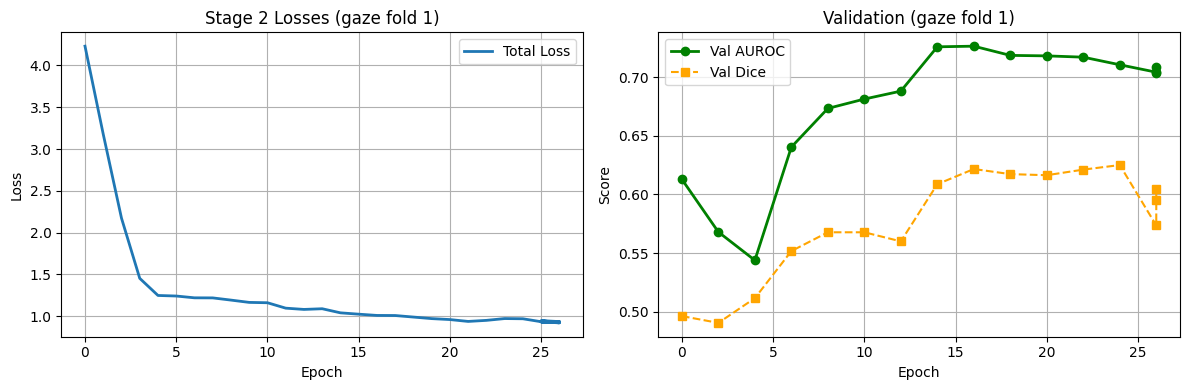

Saved /content/drive/MyDrive/DENTAL/results/stage2_training_curves.png


In [16]:
# --- Defensive Setup ---
if 'torch' not in globals(): import torch
if 'np' not in globals(): import numpy as np
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'PROJECT' not in globals():
    PROJECT = os.getcwd()
if 'REAL_TRAIN_DONE' not in globals():
    REAL_TRAIN_DONE = os.path.isfile(os.path.join(PROJECT, 'results', 'stage2_part1_negative_report.json'))

import matplotlib.pyplot as plt

# Prefer best-fold gaze history from Part 1 CV (not legacy stage2_history.json)
hist = []
hist_label = None
best_i = best_fold if 'best_fold' in globals() and best_fold is not None else None
if best_i is None:
    metrics_path = os.path.join(PROJECT, 'results', 'stage2_cv_fold_metrics.json')
    if os.path.isfile(metrics_path):
        with open(metrics_path, 'r', encoding='utf-8') as f:
            rows = json.load(f)
        if rows:
            best_i = max(range(len(rows)), key=lambda i: float(rows[i].get('val_AUROC', -1)))

if best_i is not None:
    hp = os.path.join(PROJECT, 'results', f'stage2_gaze_fold{best_i}_history.json')
    if os.path.isfile(hp):
        with open(hp, 'r', encoding='utf-8') as f:
            hist = json.load(f)
        hist_label = f'gaze fold {best_i}'

if not hist and os.path.isfile(os.path.join(PROJECT, 'results', 'stage2_history.json')):
    with open(os.path.join(PROJECT, 'results', 'stage2_history.json'), 'r') as f:
        hist = json.load(f)
    hist_label = 'legacy stage2_history'

if REAL_TRAIN_DONE and hist:
    epochs = [r['epoch'] for r in hist]
    losses = [r.get('loss', 0.0) for r in hist]
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, losses, label='Total Loss', lw=2)
    if any('main_loss' in r for r in hist):
        plt.plot(epochs, [r.get('main_loss', float('nan')) for r in hist], label='Main BCE', ls='--')
    if any('gaze_kl' in r for r in hist):
        plt.plot(epochs, [r.get('gaze_kl', float('nan')) for r in hist], label='Gaze KL', ls=':')
    plt.title(f'Stage 2 Losses ({hist_label})')
    plt.xlabel('Epoch'); plt.ylabel('Loss')
    plt.legend(); plt.grid(True)

    val_epochs = [r['epoch'] for r in hist if 'val_AUROC' in r]
    val_auroc = [r['val_AUROC'] for r in hist if 'val_AUROC' in r]
    val_dice = [r.get('val_Dice', 0.0) for r in hist if 'val_AUROC' in r]
    plt.subplot(1, 2, 2)
    if val_epochs:
        plt.plot(val_epochs, val_auroc, label='Val AUROC', marker='o', color='green', lw=2)
        plt.plot(val_epochs, val_dice, label='Val Dice', marker='s', color='orange', ls='--')
        plt.title(f'Validation ({hist_label})')
        plt.xlabel('Epoch'); plt.ylabel('Score')
        plt.legend(); plt.grid(True)
    plt.tight_layout()
    out_png = os.path.join(PROJECT, 'results', 'stage2_training_curves.png')
    plt.savefig(out_png, dpi=150)
    plt.show()
    print(f'Saved {out_png}')
else:
    print('No Part 1 fold history found to plot (expected results/stage2_gaze_fold*_history.json).')


## 11 — Final Status Banner

In [17]:
# --- Defensive Setup ---
if 'os' not in globals(): import os
if 'json' not in globals(): import json
if 'PROJECT' not in globals():
    PROJECT = os.getcwd()
if 'REAL_TRAIN_DONE' not in globals():
    REAL_TRAIN_DONE = os.path.isfile(os.path.join(PROJECT, 'results', 'stage2_part1_negative_report.json'))

from IPython.display import Markdown, display

msg = "### NB04 Stage 2 Part 1 Complete\n"
report_path = os.path.join(PROJECT, 'results', 'stage2_part1_negative_report.json')
metrics_path = os.path.join(PROJECT, 'results', 'stage2_cv_fold_metrics.json')

if REAL_TRAIN_DONE and os.path.isfile(report_path):
    with open(report_path, 'r', encoding='utf-8') as f:
        report = json.load(f)
    held = report.get('held_out_test_negative_summary') or {}
    agg = report.get('aggregate_gaze_val') or {}
    folds = report.get('cv_gaze_fold_metrics') or []
    if not folds and os.path.isfile(metrics_path):
        with open(metrics_path, 'r', encoding='utf-8') as f:
            folds = json.load(f)
    bf = best_fold if 'best_fold' in globals() and best_fold is not None else None
    if bf is None and folds:
        bf = max(range(len(folds)), key=lambda i: float(folds[i].get('val_AUROC', -1)))
    auroc_mean = (agg.get('AUROC') or {}).get('mean')
    auroc_std = (agg.get('AUROC') or {}).get('std')
    msg += f"- **Best fold (val AUROC):** {bf}\n"
    if auroc_mean is not None:
        msg += f"- **CV val AUROC:** {auroc_mean:.4f} ± {auroc_std:.4f}\n"
    if held.get('stage2_auroc') is not None:
        msg += f"- **Held-out test Stage2 AUROC:** {held['stage2_auroc']:.4f}\n"
    if held.get('stage1_auroc') is not None:
        msg += f"- **Held-out test Stage1 AUROC:** {held['stage1_auroc']:.4f}\n"
    if held.get('interpretation'):
        msg += f"- **Interpretation:** {held['interpretation']}\n"
    msg += f"- **Report:** `results/stage2_part1_negative_report.json`\n"
else:
    msg += "- Part 1 not finished yet (missing negative report).\n"
display(Markdown(msg))


### NB04 Stage 2 Part 1 Complete
- **Best fold (val AUROC):** 1
- **CV val AUROC:** 0.6773 ± 0.0475
- **Held-out test Stage2 AUROC:** 0.6266
- **Held-out test Stage1 AUROC:** 0.5847
- **Interpretation:** No significant Stage 2 improvement over Stage 1 (supports negative/null result)
- **Report:** `results/stage2_part1_negative_report.json`


## 12 — Stage 2 cross-domain eval on DENTEX

Loads the best available Stage-2 checkpoint via resolve order:
`stage2_refit_best.pth` → best CV fold (`stage2_gaze_fold*_best.pth`) → legacy `stage2_best.pth`.

Evaluates on `splits/dentex_test_split.csv` with images under `LOCAL_DATA`. Saves metrics + per-image CSV.

**Note:** Prefer NB05 after full-pool refit for the final DENTEX table. This cell is optional cross-domain smoke after Part 1.


In [18]:
# === Stage 2 DENTEX cross-domain evaluation (self-contained) ===
import os, json, sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
from sklearn.metrics import confusion_matrix

# --- Defensive setup (safe if pasted / run standalone) ---
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'LOCAL_DATA' not in globals():
    LOCAL_DATA = '/content/dental_data'
if 'PROJECT' not in globals():
    PROJECT = os.getcwd()
if 'CONFIG' not in globals():
    with open(os.path.join(PROJECT, 'config.json'), 'r') as f:
        CONFIG = json.load(f)
if 'NUM_WORKERS' not in globals():
    NUM_WORKERS = 2 if ON_GPU else 0

DENTEX_SPLIT_CSV = os.path.join(PROJECT, 'splits', 'dentex_test_split.csv')


def resolve_stage2_ckpt(project):
    """Prefer refit > best CV fold > legacy stage2_best.pth."""
    candidates = [
        os.path.join(project, 'checkpoints', 'stage2_refit_best.pth'),
        os.path.join(project, 'checkpoints', 'stage2_best.pth'),
    ]
    metrics_path = os.path.join(project, 'results', 'stage2_cv_fold_metrics.json')
    if os.path.isfile(metrics_path):
        with open(metrics_path, 'r', encoding='utf-8') as f:
            rows = json.load(f)
        if rows:
            best = max(rows, key=lambda r: float(r.get('val_AUROC', -1)))
            ck = best.get('checkpoint') or f"checkpoints/stage2_gaze_fold{best['fold']}_best.pth"
            candidates.insert(1, os.path.join(project, ck) if not os.path.isabs(ck) else ck)
    for p in candidates:
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        'No Stage-2 checkpoint found. Expected stage2_refit_best.pth, '
        'stage2_gaze_fold*_best.pth, or legacy stage2_best.pth. '
        'Finish NB04 Part 1 (or NB05 refit) first.'
    )


STAGE2_CKPT = resolve_stage2_ckpt(PROJECT)
print(f'Using Stage-2 checkpoint: {STAGE2_CKPT}')

def _resolve_dentex_image_root(split_csv):
    """image_path in CSV is relative to LOCAL_DATA (e.g. data/dentex/.../val_1.png)."""
    if not os.path.isfile(split_csv):
        raise FileNotFoundError(f'Missing {split_csv} — run NB00 first.')
    df = pd.read_csv(split_csv)
    if len(df) == 0:
        raise RuntimeError('dentex_test_split.csv is empty.')
    rel = str(df['image_path'].iloc[0])
    for root in (LOCAL_DATA, PROJECT):
        if os.path.isfile(os.path.join(root, rel)):
            return root
    # Helpful hint if user only unzipped under test_data
    hint_dirs = [
        os.path.join(LOCAL_DATA, 'data', 'dentex', 'quadrant_enumeration_disease', 'xrays'),
        os.path.join(LOCAL_DATA, 'data', 'dentex', 'test_data'),
    ]
    for d in hint_dirs:
        if os.path.isdir(d):
            n = sum(1 for f in os.listdir(d) if f.lower().endswith(('.png', '.jpg')))
            print(f'Found {n} images under {d} (split expects paths like {rel})')
    raise FileNotFoundError(
        f'Cannot find DENTEX image at {os.path.join(LOCAL_DATA, rel)}. '
        'Unzip DENTEX so LOCAL_DATA contains data/dentex/quadrant_enumeration_disease/xrays/*.png'
    )

if not ON_GPU:
    print('CPU: building loader only; set GPU for full eval.')
else:
    if 'cache_project_modules' in globals():
        cache_project_modules(PROJECT)
    if 'build_model_and_optimizer' not in globals():
        raise RuntimeError('Run NB04 model cell first (defines build_model_and_optimizer).')
    if 'compute_metrics' not in globals() or 'calibrate_decision_threshold' not in globals():
        from core_modules import compute_metrics, calibrate_decision_threshold

    if not os.path.isfile(STAGE2_CKPT):
        raise FileNotFoundError(f'Missing {STAGE2_CKPT} — complete Stage 2 training first.')

    img_root = _resolve_dentex_image_root(DENTEX_SPLIT_CSV)
    print(f'DENTEX image_root: {img_root}')

    from dental_dataset import DentalDataset
    dentex_ds = DentalDataset(DENTEX_SPLIT_CSV, PROJECT, augment=False, image_root=img_root)
    dentex_df = dentex_ds.df.copy()
    labeled = dentex_df[dentex_df['has_lesion_gt'].isin([0, 1])].copy()
    print(f'DENTEX total: {len(dentex_df)} | labeled (0/1): {len(labeled)} | '
          f'pos={int((labeled["has_lesion_gt"]==1).sum())} neg={int((labeled["has_lesion_gt"]==0).sum())}')

    # Smoke-check one image load
    try:
        _s = dentex_ds[0]
        assert _s['image'].shape[-1] == 224
    except Exception as exc:
        raise RuntimeError(f'DentalDataset failed to load DENTEX image: {exc}')

    bs = CONFIG.get('chosen_batch_size', 64)
    nw = 0 if os.name == 'nt' else NUM_WORKERS
    dentex_loader = DataLoader(dentex_ds, batch_size=bs, shuffle=False, num_workers=nw, pin_memory=ON_GPU)

    ckpt = torch.load(STAGE2_CKPT, map_location=device)
    model, _ = build_model_and_optimizer(CONFIG, device, load_stage1=False)
    model.load_state_dict(ckpt['model'])
    model.eval()
    print(f'Loaded Stage 2 best (epoch {ckpt.get("epoch", "?")})')

    ids, targets, probs = [], [], []
    with torch.no_grad():
        for batch in tqdm(dentex_loader, desc='DENTEX Stage2', unit='batch'):
            logits, _, _, _ = model(batch['image'].to(device))
            p = torch.sigmoid(logits.squeeze(-1)).detach().cpu().numpy()
            probs.extend(p.tolist())
            targets.extend(batch['has_lesion_gt'].tolist())
            ids.extend(batch.get('image_id', batch.get('id', [])))

    ids = np.array(ids)
    targets = np.array(targets)
    probs = np.array(probs)

    # Metrics on labeled subset only (has_lesion_gt in {0,1})
    mask_l = np.isin(targets, [0, 1])
    t_lab, p_lab = targets[mask_l], probs[mask_l]
    opt_thresh = calibrate_decision_threshold(t_lab, p_lab)
    preds_lab = (p_lab > opt_thresh).astype(int)
    metrics = compute_metrics(t_lab, preds_lab, p_lab)
    metrics['opt_threshold'] = float(opt_thresh)
    metrics['n_total'] = int(len(targets))
    metrics['n_labeled'] = int(mask_l.sum())
    metrics['n_unlabeled'] = int((~mask_l).sum())

    preds_all = (probs > opt_thresh).astype(int)
    cm = confusion_matrix(t_lab, preds_lab)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    print(f"\n{'='*55}\n  STAGE 2 DENTEX (labeled only, thresh={opt_thresh:.3f})\n{'='*55}")
    print(f"  TN: {tn:5d}  |  FP: {fp:5d}")
    print(f"  FN: {fn:5d}  |  TP: {tp:5d}")
    print(f"  Dice={metrics['Dice']:.4f}  F1={metrics['F1']:.4f}  "
          f"Recall={metrics['Recall']:.4f}  AUROC={metrics['AUROC']:.4f}")

    os.makedirs(os.path.join(PROJECT, 'results'), exist_ok=True)
    out_metrics = os.path.join(PROJECT, 'results', 'stage2_dentex_metrics.json')
    out_csv = os.path.join(PROJECT, 'results', 'stage2_dentex_per_image_predictions.csv')
    with open(out_metrics, 'w') as f:
        json.dump(metrics, f, indent=2)
    pd.DataFrame({
        'id': ids,
        'has_lesion_gt': targets,
        'prob': probs,
        'pred': preds_all,
    }).to_csv(out_csv, index=False)
    print(f'Saved {out_metrics}')
    print(f'Saved {out_csv}')

Using Stage-2 checkpoint: /content/drive/MyDrive/DENTAL/checkpoints/stage2_gaze_fold1_best.pth
DENTEX image_root: /content/dental_data
DENTEX total: 1871 | labeled (0/1): 1005 | pos=936 neg=69


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
 cls_seg_blend (MIL): 0.5
Loaded Stage 2 best (epoch 16)


DENTEX Stage2: 100%|██████████| 30/30 [02:51<00:00,  5.72s/batch]



  STAGE 2 DENTEX (labeled only, thresh=0.262)
  TN:     7  |  FP:    62
  FN:    68  |  TP:   868
  Dice=0.9303  F1=0.9303  Recall=0.9274  AUROC=0.4536
Saved /content/drive/MyDrive/DENTAL/results/stage2_dentex_metrics.json
Saved /content/drive/MyDrive/DENTAL/results/stage2_dentex_per_image_predictions.csv


In [19]:
# Duplicate DENTEX cell removed - use the cell above (canonical DENTEX eval).
print('Skipped duplicate DENTEX cell. Canonical eval is the previous code cell.')


Skipped duplicate DENTEX cell. Canonical eval is the previous code cell.


In [20]:
# === Stage 2 OralXray cross-domain evaluation (self-contained) ===
import os, json, sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
from sklearn.metrics import confusion_matrix

# --- Defensive setup ---
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'LOCAL_DATA' not in globals():
    LOCAL_DATA = '/content/dental_data'
if 'PROJECT' not in globals():
    PROJECT = os.getcwd()
if 'CONFIG' not in globals():
    with open(os.path.join(PROJECT, 'config.json'), 'r') as f:
        CONFIG = json.load(f)
if 'NUM_WORKERS' not in globals():
    NUM_WORKERS = 2 if ON_GPU else 0


def resolve_stage2_ckpt(project):
    """Prefer refit > best CV fold > legacy stage2_best.pth."""
    candidates = [
        os.path.join(project, 'checkpoints', 'stage2_refit_best.pth'),
        os.path.join(project, 'checkpoints', 'stage2_best.pth'),
    ]
    metrics_path = os.path.join(project, 'results', 'stage2_cv_fold_metrics.json')
    if os.path.isfile(metrics_path):
        with open(metrics_path, 'r', encoding='utf-8') as f:
            rows = json.load(f)
        if rows:
            best = max(rows, key=lambda r: float(r.get('val_AUROC', -1)))
            ck = best.get('checkpoint') or f"checkpoints/stage2_gaze_fold{best['fold']}_best.pth"
            candidates.insert(1, os.path.join(project, ck) if not os.path.isabs(ck) else ck)
    for p in candidates:
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        'No Stage-2 checkpoint found. Expected stage2_refit_best.pth, '
        'stage2_gaze_fold*_best.pth, or legacy stage2_best.pth.'
    )


STAGE2_CKPT = resolve_stage2_ckpt(PROJECT)
print(f'Using Stage-2 checkpoint: {STAGE2_CKPT}')

if not ON_GPU:
    print('CPU: skipping OralXray eval on CPU dry run.')
else:
    if 'build_model_and_optimizer' not in globals():
        raise RuntimeError('Run NB04 model cell first.')
    if 'compute_metrics' not in globals():
        from core_modules import compute_metrics, calibrate_decision_threshold
    if not os.path.isfile(STAGE2_CKPT):
        raise FileNotFoundError(f'Missing {STAGE2_CKPT}')

    from dental_dataset import build_dataloaders
    img_root = LOCAL_DATA if os.path.isdir(LOCAL_DATA) else PROJECT
    loaders = build_dataloaders(CONFIG, PROJECT, image_root=img_root, fold=0)
    if 'oralxray_test' not in loaders or loaders['oralxray_test'] is None:
        raise RuntimeError('oralxray_test loader not built. Check dataset paths.')
    oral_loader = loaders['oralxray_test']

    print(f'OralXray total: {len(oral_loader.dataset)} (image_root={img_root})')

    ckpt = torch.load(STAGE2_CKPT, map_location=device)
    model, _ = build_model_and_optimizer(CONFIG, device, load_stage1=False)
    model.load_state_dict(ckpt['model'])
    model.eval()
    print(f'Loaded Stage 2 ckpt (epoch {ckpt.get("epoch", "?")})')

    ids, targets, probs = [], [], []
    with torch.no_grad():
        for batch in tqdm(oral_loader, desc='OralXray Stage2'):
            logits, _, _, _ = model(batch['image'].to(device))
            p = torch.sigmoid(logits.squeeze(-1)).cpu().numpy()
            probs.extend(p.tolist())
            targets.extend(batch['has_lesion_gt'].tolist())
            ids.extend(batch.get('image_id', batch.get('id', [])))

    targets, probs = np.array(targets), np.array(probs)
    mask_l = np.isin(targets, [0, 1])
    t_lab, p_lab = targets[mask_l], probs[mask_l]
    opt_thresh = calibrate_decision_threshold(t_lab, p_lab)
    preds_lab = (p_lab > opt_thresh).astype(int)
    metrics = compute_metrics(t_lab, preds_lab, p_lab)
    metrics.update({
        'opt_threshold': float(opt_thresh),
        'n_total': len(targets),
        'n_labeled': int(mask_l.sum()),
        'n_unlabeled': int((~mask_l).sum()),
        'checkpoint': STAGE2_CKPT,
    })

    cm = confusion_matrix(t_lab, preds_lab)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    print(f"\nSTAGE 2 ORALXRAY | thresh={opt_thresh:.3f}")
    print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
    print(f"Dice={metrics['Dice']:.4f} AUROC={metrics['AUROC']:.4f}")

    os.makedirs(os.path.join(PROJECT, 'results'), exist_ok=True)
    out_m = os.path.join(PROJECT, 'results', 'stage2_oralxray_metrics.json')
    out_c = os.path.join(PROJECT, 'results', 'stage2_oralxray_per_image_predictions.csv')
    with open(out_m, 'w') as f:
        json.dump(metrics, f, indent=2)
    pd.DataFrame({
        'id': ids, 'has_lesion_gt': targets, 'prob': probs,
        'pred': (probs > opt_thresh).astype(int),
    }).to_csv(out_c, index=False)
    print(f'Saved {out_m}')
    print(f'Saved {out_c}')


Using Stage-2 checkpoint: /content/drive/MyDrive/DENTAL/checkpoints/stage2_gaze_fold1_best.pth
OralXray total: 1269 (image_root=/content/dental_data)


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
 cls_seg_blend (MIL): 0.5
Loaded Stage 2 ckpt (epoch 16)


OralXray Stage2: 100%|██████████| 20/20 [00:36<00:00,  1.81s/it]


STAGE 2 ORALXRAY | thresh=0.523
TN=23 FP=1 FN=174 TP=1071
Dice=0.9245 AUROC=0.9482
Saved /content/drive/MyDrive/DENTAL/results/stage2_oralxray_metrics.json
Saved /content/drive/MyDrive/DENTAL/results/stage2_oralxray_per_image_predictions.csv


In [21]:
# === Post-NB04 Automated Checklist Verification ===
import os
import json
import inspect

try:
    from IPython.display import Markdown, display
    _HAS_IPY = True
except ImportError:
    _HAS_IPY = False


def run_post_run_checklist():
    project = globals().get('PROJECT') or os.getcwd()
    if not os.path.isfile(os.path.join(project, 'config.json')):
        # cwd may be Notebooks/
        alt = os.path.abspath(os.path.join(os.getcwd(), '..'))
        if os.path.isfile(os.path.join(alt, 'config.json')):
            project = alt
    results_dir = os.path.join(project, 'results')
    ckpt_dir = os.path.join(project, 'checkpoints')
    image_root = globals().get('LOCAL_DATA') or project

    with open(os.path.join(project, 'config.json'), 'r', encoding='utf-8') as f:
        cfg = json.load(f)

    num_folds = int(cfg.get('num_folds', 5))
    run_ablation = bool(cfg.get('run_gaze_ablation', False))
    notes = []

    a_checks = {}
    a_details = {}

    # A1: Stage 1 checkpoint present
    s1_path = os.path.join(ckpt_dir, 'stage1_best.pth')
    a_checks['A1: Stage 1 checkpoint exists'] = os.path.isfile(s1_path)
    a_details['A1'] = s1_path

    # A2: All gaze fold best checkpoints
    missing_gaze = [
        f'stage2_gaze_fold{i}_best.pth'
        for i in range(num_folds)
        if not os.path.isfile(os.path.join(ckpt_dir, f'stage2_gaze_fold{i}_best.pth'))
    ]
    a_checks['A2: All gaze folds finished'] = len(missing_gaze) == 0
    a_details['A2_missing'] = missing_gaze

    # A3: Ablation folds (if configured)
    if run_ablation:
        missing_abl = [
            f'stage2_ablation_fold{i}_best.pth'
            for i in range(num_folds)
            if not os.path.isfile(os.path.join(ckpt_dir, f'stage2_ablation_fold{i}_best.pth'))
        ]
        a_checks['A3: All ablation folds finished'] = len(missing_abl) == 0
        a_details['A3_missing'] = missing_abl
    else:
        a_checks['A3: Ablation skipped (by config)'] = True
        a_details['A3'] = 'run_gaze_ablation=false'

    # A4: Negative report
    report_path = os.path.join(results_dir, 'stage2_part1_negative_report.json')
    a_checks['A4: Negative report generated'] = os.path.isfile(report_path)
    report_data = {}
    if a_checks['A4: Negative report generated']:
        try:
            with open(report_path, 'r', encoding='utf-8') as f:
                report_data = json.load(f)
        except (OSError, json.JSONDecodeError) as exc:
            a_checks['A4: Negative report generated'] = False
            a_details['A4_error'] = str(exc)
            notes.append(f'A4: report unreadable: {exc}')

    # A5: Healthy masks strictly zero (live verify)
    a5_ok = False
    try:
        from dental_dataset import verify_tufts_anomaly_masks
        ok, msg = verify_tufts_anomaly_masks(
            project, image_root=image_root, csv_relpath='splits/train_split.csv',
        )
        a5_ok = bool(ok)
        a_details['A5'] = msg
        if not ok:
            notes.append(f'A5: {msg}')
    except Exception as exc:
        a5_ok = False
        a_details['A5'] = f'verify failed: {exc}'
        notes.append(f'A5 exception: {exc}')
    a_checks['A5: Healthy masks strictly zero'] = a5_ok

    # A6: Not a smoke run
    smoke = None
    if 'SMOKE_TEST' in globals():
        smoke = bool(globals()['SMOKE_TEST'])
    status_path = os.path.join(results_dir, 'stage2_status.json')
    if smoke is None and os.path.isfile(status_path):
        try:
            with open(status_path, 'r', encoding='utf-8') as f:
                smoke = bool(json.load(f).get('smoke_test', True))
        except (OSError, json.JSONDecodeError):
            smoke = True
    if smoke is None:
        # Infer from gaze histories: smoke usually has 1 epoch
        short = 0
        for i in range(num_folds):
            hp = os.path.join(results_dir, f'stage2_gaze_fold{i}_history.json')
            if os.path.isfile(hp):
                try:
                    with open(hp, 'r', encoding='utf-8') as f:
                        hist = json.load(f)
                    if isinstance(hist, list) and len(hist) <= 1:
                        short += 1
                except (OSError, json.JSONDecodeError):
                    pass
        smoke = short == num_folds and short > 0
        a_details['A6_inferred_from_history'] = True
    a_checks['A6: SMOKE_TEST is False'] = not bool(smoke)
    a_details['A6_smoke'] = smoke

    # A7: Resume / recipe consistency (no contaminated incomplete set)
    a7_ok = True
    a7_notes = []
    # Old single-split ckpt present while fold CV incomplete → contamination risk
    old_best = os.path.isfile(os.path.join(ckpt_dir, 'stage2_best.pth'))
    if old_best and missing_gaze:
        a7_ok = False
        a7_notes.append('old stage2_best.pth present while fold bests incomplete')
    # Report fold count must match config
    if report_data:
        rep_folds = int(report_data.get('num_folds', -1))
        if rep_folds != num_folds:
            a7_ok = False
            a7_notes.append(f'report num_folds={rep_folds} != config {num_folds}')
        snap = report_data.get('config_snapshot') or {}
        for key in ('gaze_lambda', 'stage2_mix_oral', 'run_gaze_ablation'):
            if key in snap and key in cfg and snap[key] != cfg[key]:
                a7_ok = False
                a7_notes.append(f'config drift {key}: report={snap[key]} now={cfg[key]}')
    # Each finished gaze fold should have a history with >=1 epoch
    for i in range(num_folds):
        best_p = os.path.join(ckpt_dir, f'stage2_gaze_fold{i}_best.pth')
        hist_p = os.path.join(results_dir, f'stage2_gaze_fold{i}_history.json')
        if os.path.isfile(best_p) and not os.path.isfile(hist_p):
            a7_ok = False
            a7_notes.append(f'missing history for gaze fold {i}')
    a_checks['A7: Resume/recipe consistency'] = a7_ok
    a_details['A7'] = a7_notes or 'ok'
    notes.extend(a7_notes)

    # A8: Dice empty-mask fix present in core_modules
    a8_ok = False
    try:
        import core_modules as cm
        src = inspect.getsource(cm.dice_loss_with_logits)
        a8_ok = (
            'has_lesion' in src
            and 'sum() == 0' in src
            and 'loss_per_image' in src
        )
        a_details['A8'] = 'dice_loss_with_logits has empty-mask gate' if a8_ok else 'empty-mask gate NOT found'
        if not a8_ok:
            notes.append('A8: Dice empty-mask fix missing in loaded core_modules')
    except Exception as exc:
        a8_ok = False
        a_details['A8'] = str(exc)
        notes.append(f'A8 exception: {exc}')
    a_checks['A8: Dice empty-mask fix present'] = a8_ok

    # ---------------------------------------------------------
    # Section B
    # ---------------------------------------------------------
    b_checks = {}
    held = report_data.get('held_out_test_negative_summary') or {}
    b_checks['B1: Held-out test numbers present'] = bool(held) and (
        'stage1_auroc' in held or 'stage2_auroc' in held
    )
    b_checks['B2: CV summary present'] = os.path.isfile(
        os.path.join(results_dir, 'stage2_cv_fold_metrics.json')
    )
    b_checks['B3: Stage1 baseline recorded'] = (
        'cv_stage1_fold_metrics' in report_data
        or ('stage1_auroc' in held)
    )
    b_checks['B4: Paired diff / interpretation'] = (
        'paired_auroc_diff_stage2_minus_stage1' in held
        and 'interpretation' in held
    )
    b_checks['B5: Predictions CSV exists'] = os.path.isfile(
        os.path.join(results_dir, 'stage2_part1_test_predictions.csv')
    )
    missing_hist = [
        i for i in range(num_folds)
        if not os.path.isfile(os.path.join(results_dir, f'stage2_gaze_fold{i}_history.json'))
    ]
    b_checks['B6: Histories saved'] = len(missing_hist) == 0
    a_details['B6_missing_hist'] = missing_hist

    a_passed = all(a_checks.values())
    b_passed = all(b_checks.values())
    if a_passed and b_passed:
        verdict = 'GREEN'
        verdict_msg = (
            'All critical checks passed and exports look complete. '
            'FREEZE weights and proceed to faithfulness. Do NOT re-run to chase AUROC.'
        )
    elif a_passed and not b_passed:
        verdict = 'YELLOW'
        verdict_msg = (
            'Critical training checks passed, but some exports/quality files are missing. '
            'Usually no full retrain — recover eval/exports from checkpoints if possible.'
        )
    else:
        verdict = 'RED'
        verdict_msg = (
            'One or more Section A checks failed. Run is incomplete or contaminated. '
            'RE-RUN (or finish remaining folds with resume) before reporting.'
        )

    out = {
        'verdict': verdict,
        'verdict_msg': verdict_msg,
        'section_a': a_checks,
        'section_b': b_checks,
        'details': a_details,
        'notes': notes,
        'num_folds': num_folds,
        'run_gaze_ablation': run_ablation,
        'project': project,
    }
    os.makedirs(results_dir, exist_ok=True)
    out_path = os.path.join(results_dir, 'stage2_post_run_checklist.json')
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(out, f, indent=2)
    print(f'Saved {out_path}')

    def _row(name, passed):
        return f"| {name} | {'PASS' if passed else 'FAIL'} |"

    md = [
        '## Post-NB04 Automated Checklist',
        '',
        '### Section A: Critical Integrity (Must-Pass)',
        '| Check | Status |',
        '|---|---|',
    ]
    for k, v in a_checks.items():
        md.append(_row(k, v))
    md += [
        '',
        '### Section B: Quality & Export Completeness',
        '| Check | Status |',
        '|---|---|',
    ]
    for k, v in b_checks.items():
        md.append(_row(k, v))
    md += ['', '### FINAL VERDICT', f'> **{verdict}** — {verdict_msg}']
    if notes:
        md += ['', '### Notes']
        for n in notes:
            md.append(f'- {n}')

    text = '\n'.join(md)
    if _HAS_IPY:
        display(Markdown(text))
    else:
        print(text)
    return out


run_post_run_checklist()


Saved /content/drive/MyDrive/DENTAL/results/stage2_post_run_checklist.json


## Post-NB04 Automated Checklist

### Section A: Critical Integrity (Must-Pass)
| Check | Status |
|---|---|
| A1: Stage 1 checkpoint exists | PASS |
| A2: All gaze folds finished | PASS |
| A3: All ablation folds finished | PASS |
| A4: Negative report generated | PASS |
| A5: Healthy masks strictly zero | PASS |
| A6: SMOKE_TEST is False | PASS |
| A7: Resume/recipe consistency | PASS |
| A8: Dice empty-mask fix present | PASS |

### Section B: Quality & Export Completeness
| Check | Status |
|---|---|
| B1: Held-out test numbers present | PASS |
| B2: CV summary present | PASS |
| B3: Stage1 baseline recorded | PASS |
| B4: Paired diff / interpretation | PASS |
| B5: Predictions CSV exists | PASS |
| B6: Histories saved | PASS |

### FINAL VERDICT
> **GREEN** — All critical checks passed and exports look complete. FREEZE weights and proceed to faithfulness. Do NOT re-run to chase AUROC.

{'verdict': 'GREEN',
 'verdict_msg': 'All critical checks passed and exports look complete. FREEZE weights and proceed to faithfulness. Do NOT re-run to chase AUROC.',
 'section_a': {'A1: Stage 1 checkpoint exists': True,
  'A2: All gaze folds finished': True,
  'A3: All ablation folds finished': True,
  'A4: Negative report generated': True,
  'A5: Healthy masks strictly zero': True,
  'A6: SMOKE_TEST is False': True,
  'A7: Resume/recipe consistency': True,
  'A8: Dice empty-mask fix present': True},
 'section_b': {'B1: Held-out test numbers present': True,
  'B2: CV summary present': True,
  'B3: Stage1 baseline recorded': True,
  'B4: Paired diff / interpretation': True,
  'B5: Predictions CSV exists': True,
  'B6: Histories saved': True},
 'details': {'A1': '/content/drive/MyDrive/DENTAL/checkpoints/stage1_best.pth',
  'A2_missing': [],
  'A3_missing': [],
  'A5': 'OK: 32/32 lesion samples have mask pixels; 0/8 healthy samples nonzero (expect 0)',
  'A6_smoke': False,
  'A7': 'ok'